<div>
<img src="https://www.ul.ie/themes/custom/ul/logo.jpg" />
</div>

#**MSc in Artificial Intelligence and Machine Learning**
##CS6271 - Evolutionary Algorithms and Humanoid Robotics 2025
### Kaggle Competition


Module Leader: Conor Ryan

Developer: ADAM GREENAN 

Student ID: 21306729

Predict the forest cover type (**Spruce/Fir** vs **Lodgepole Pine**) of 30m x 30m patches of land in Roosevelt National Forest, Colorado, using only cartographic and environmental measurements. This is a binary version of the Forest Covertype dataset (Blackard, Dean & Anderson, Colorado State University / USDA Forest Service).

In [1]:
# Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Dataset

**Class (`Cover_Type`):**

- `1` - Spruce / Fir
- `2` - Lodgepole Pine

Internally the classes are re-coded to `0` (Spruce/Fir) and `1` (Lodgepole Pine) so the evolved boolean expressions can be compared directly with the labels. They are converted back to `1` / `2` when the submission file is written.

**Listing of features (54, raw and unscaled, no missing values):**

*Continuous topographic / environmental variables*

- `Elevation`
- `Aspect`
- `Slope`
- `Horizontal_Distance_To_Hydrology`
- `Vertical_Distance_To_Hydrology`
- `Horizontal_Distance_To_Roadways`
- `Hillshade_9am`
- `Hillshade_Noon`
- `Hillshade_3pm`
- `Horizontal_Distance_To_Fire_Points`

*Binary indicators*

- `Wilderness_Area1` ... `Wilderness_Area4` (4 features)
- `Soil_Type1` ... `Soil_Type40` (40 features)

**Files:** `train.csv` (5,000 labelled rows) and `test.csv` (490,141 unlabelled rows), expected in the same folder as this notebook.

**Metric:** accuracy. **Submission format:** `id,Cover_Type` with `id` from 0 to 490140 and `Cover_Type` in {1, 2}.

In [2]:
# Suppressing Warnings:
import warnings
warnings.filterwarnings("ignore")

## Setup

Genetic Programming uses the DEAP library (no GRAPE needed).

In [3]:
%pip install -q deap

import os

Note: you may need to restart the kernel to use updated packages.


## Train set

In [4]:
# train.csv and test.csv are in the same folder as this notebook
DATA_DIR = '.'

train_file = os.path.join(DATA_DIR, 'train.csv')
df_train = pd.read_csv(train_file)
print(df_train.shape)
df_train.head()

(5000, 55)


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,3222,302,14,0,0,3542,179,233,193,1798,...,0,0,0,0,0,0,0,0,0,1
1,3174,142,15,228,41,1022,241,235,119,2045,...,0,0,0,0,0,0,0,0,0,1
2,3114,182,6,638,73,450,222,244,157,1684,...,0,0,0,0,0,0,0,0,0,2
3,3088,2,24,660,62,920,179,186,138,1436,...,0,0,0,0,0,0,0,0,0,1
4,3204,315,12,541,29,655,188,230,182,966,...,1,0,0,0,0,0,0,0,0,2


In [5]:
df_train.describe()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,...,5000.000000,5000.000000,5000.000000,5000.000000,5000.0,5000.0,5000.000000,5000.00000,5000.000000,5000.000000
mean,3008.003200,154.115800,13.341600,275.389200,44.645000,2524.380600,213.046600,224.617800,143.521200,2080.224000,...,0.099400,0.087000,0.003200,0.002400,0.0,0.0,0.014400,0.01540,0.010800,1.572200
std,203.003201,111.539144,7.008761,212.906781,57.240275,1570.933932,25.170497,18.138509,36.054375,1344.334161,...,0.299228,0.281863,0.056484,0.048936,0.0,0.0,0.119145,0.12315,0.103371,0.494809
min,2154.000000,0.000000,0.000000,0.000000,-152.000000,30.000000,56.000000,100.000000,0.000000,30.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.00000,0.000000,1.000000
25%,2879.000000,57.000000,8.000000,108.000000,7.000000,1244.500000,200.000000,215.000000,121.000000,1142.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.00000,0.000000,1.000000
50%,3018.000000,124.000000,12.000000,234.000000,28.000000,2230.000000,218.000000,227.000000,144.000000,1801.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.00000,0.000000,2.000000
75%,3164.000000,256.000000,17.000000,395.000000,66.000000,3554.000000,231.000000,237.000000,168.000000,2621.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.00000,0.000000,2.000000
max,3667.000000,359.000000,51.000000,1248.000000,455.000000,7039.000000,254.000000,254.000000,248.000000,6930.000000,...,1.000000,1.000000,1.000000,1.000000,0.0,0.0,1.000000,1.00000,1.000000,2.000000


In [6]:
# class balance (1 = Spruce/Fir, 2 = Lodgepole Pine)
df_train['Cover_Type'].value_counts()

2    2861
1    2139
Name: Cover_Type, dtype: int64

## Feature engineering

Elevation adjusted for distance to water, and combinations of the horizontal distances, are known to separate the cover types much better than the raw columns. They are added to both the train and the test set; they are continuous, so they are standardised and become extra terminals automatically.

In [7]:
def add_features(d):
    d = d.copy()
    d['Hydro_Euclid'] = np.hypot(d['Horizontal_Distance_To_Hydrology'], d['Vertical_Distance_To_Hydrology'])
    d['Elev_m_VDH']   = d['Elevation'] - d['Vertical_Distance_To_Hydrology']
    d['Elev_m_HDH']   = d['Elevation'] - 0.2 * d['Horizontal_Distance_To_Hydrology']
    d['Hydro_p_Fire'] = d['Horizontal_Distance_To_Hydrology'] + d['Horizontal_Distance_To_Fire_Points']
    d['Hydro_m_Fire'] = d['Horizontal_Distance_To_Hydrology'] - d['Horizontal_Distance_To_Fire_Points']
    d['Hydro_p_Road'] = d['Horizontal_Distance_To_Hydrology'] + d['Horizontal_Distance_To_Roadways']
    d['Hydro_m_Road'] = d['Horizontal_Distance_To_Hydrology'] - d['Horizontal_Distance_To_Roadways']
    d['Fire_p_Road']  = d['Horizontal_Distance_To_Fire_Points'] + d['Horizontal_Distance_To_Roadways']
    d['Fire_m_Road']  = d['Horizontal_Distance_To_Fire_Points'] - d['Horizontal_Distance_To_Roadways']
    d['Elev_m_HDH3']   = d['Elevation'] - 0.3 * d['Horizontal_Distance_To_Hydrology']
    d['Elev_m_Hydro3'] = d['Elevation'] - 0.3 * d['Hydro_Euclid']
    return d

# safe to re-run: the engineered columns are simply overwritten
df_train = add_features(df_train)
print(df_train.shape)

(5000, 66)


In [8]:
TARGET = 'Cover_Type'
ID_COL = 'id'   # dropped if present

feature_cols = [c for c in df_train.columns if c not in (TARGET, ID_COL)]

# warning: re-running this cell is safe, it always rebuilds from df_train
X_train_df = df_train[feature_cols].copy()

# 0 = Spruce/Fir (class 1), 1 = Lodgepole Pine (class 2)
assert set(df_train[TARGET].unique()) <= {1, 2}
Y_train = (df_train[TARGET] == 2).astype(int).to_numpy()

print(len(feature_cols), 'features (54 original + 11 engineered)')

65 features (54 original + 11 engineered)


## Test set: **No labels**

In [9]:
test_file = os.path.join(DATA_DIR, 'test.csv')
df_test = pd.read_csv(test_file)
print(df_test.shape)
df_test.head()

(490141, 54)


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40
0,2729,320,12,30,9,1273,190,229,179,2203,...,0,0,0,0,0,0,0,0,0,0
1,3144,336,18,175,5,2439,177,212,173,469,...,0,0,1,0,0,0,0,0,0,0
2,3079,353,8,234,59,4406,206,226,158,2337,...,0,0,0,0,0,0,0,0,0,0
3,3390,183,14,720,184,1761,223,249,155,1440,...,0,0,0,0,0,0,0,1,0,0
4,2740,78,6,361,32,1518,227,230,137,1742,...,0,0,0,0,0,0,0,0,0,0


In [10]:
df_test.describe()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40
count,490141.000000,490141.000000,490141.000000,490141.000000,490141.000000,490141.000000,490141.000000,490141.000000,490141.000000,490141.000000,...,490141.000000,490141.000000,490141.000000,490141.000000,490141.000000,490141.000000,490141.0,490141.000000,490141.000000,490141.000000
mean,3009.820080,153.801945,13.369641,275.916695,44.285922,2508.651890,213.054872,224.514205,143.363320,2100.374345,...,0.050628,0.102862,0.087773,0.003079,0.001899,0.000114,0.0,0.019172,0.016654,0.010413
std,202.811748,111.625604,6.985409,213.154791,57.150450,1570.846937,24.893453,18.387231,36.149628,1348.848755,...,0.219238,0.303779,0.282964,0.055401,0.043541,0.010688,0.0,0.137130,0.127973,0.101513
min,2142.000000,0.000000,0.000000,0.000000,-173.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
25%,2881.000000,57.000000,8.000000,108.000000,6.000000,1237.000000,200.000000,214.000000,121.000000,1142.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
50%,3019.000000,125.000000,12.000000,234.000000,28.000000,2197.000000,218.000000,227.000000,143.000000,1837.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
75%,3165.000000,256.000000,17.000000,391.000000,65.000000,3523.000000,231.000000,238.000000,168.000000,2649.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
max,3686.000000,360.000000,66.000000,1397.000000,601.000000,7117.000000,254.000000,254.000000,254.000000,7173.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000


In [11]:
df_test = add_features(df_test)

# same columns, same order as the training features
X_test_df = df_test[feature_cols].copy()

# ids for the submission file (use the id column if test.csv has one)
test_ids = df_test[ID_COL].to_numpy() if ID_COL in df_test.columns else np.arange(len(df_test))
print(X_test_df.shape, test_ids.min(), test_ids.max())

(490141, 65) 0 490140


## Pre-processing

All features are numeric, so no categorical encoding is needed. The 21 continuous features (10 original + 11 engineered) have very different ranges (e.g. `Elevation` in the thousands, `Slope` in tens), which makes it hard for evolution to find useful constants. They are therefore **standardised (z-score) using the training set mean and standard deviation only**, and the same transformation is applied to the test set. The 44 binary indicators (`Wilderness_Area*`, `Soil_Type*`) are left as 0/1 and used directly as terminals.

A stratified 80/20 split of the training data is also held out as a validation set, so we get an honest estimate of generalisation (the test set is ~100x larger than the training set). Set `VAL_FRACTION = 0` to train on all 5,000 rows.

In [12]:
from sklearn.model_selection import train_test_split

binary_cols = [c for c in feature_cols if c.startswith('Wilderness_Area') or c.startswith('Soil_Type')]
cont_cols   = [c for c in feature_cols if c not in binary_cols]
print('continuous:', cont_cols)
print('binary    :', len(binary_cols), 'columns')

# z-score the continuous features with TRAIN statistics only
mu = X_train_df[cont_cols].mean()
sd = X_train_df[cont_cols].std().replace(0, 1)

X_train_s = X_train_df.copy()
X_test_s  = X_test_df.copy()
X_train_s[cont_cols] = (X_train_s[cont_cols] - mu) / sd
X_test_s[cont_cols]  = (X_test_s[cont_cols]  - mu) / sd

# hold out a validation set
VAL_FRACTION = 0.2
SPLIT_SEED = 42
if VAL_FRACTION > 0:
    idx_tr, idx_val = train_test_split(np.arange(len(X_train_s)), test_size=VAL_FRACTION,
                                       stratify=Y_train, random_state=SPLIT_SEED)
else:
    idx_tr, idx_val = np.arange(len(X_train_s)), np.array([], dtype=int)

continuous: ['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points', 'Hydro_Euclid', 'Elev_m_VDH', 'Elev_m_HDH', 'Hydro_p_Fire', 'Hydro_m_Fire', 'Hydro_p_Road', 'Hydro_m_Road', 'Fire_p_Road', 'Fire_m_Road', 'Elev_m_HDH3', 'Elev_m_Hydro3']
binary    : 44 columns


## Genetic Programming (DEAP)

This version evolves a **GP tree**, using the same data, standardisation and engineered features as above. A tree is built from

- **arithmetic** primitives `add`, `sub`, `mul`, protected division `pdiv`,
- **logic / comparison** primitives `lt`, `gt`, `and_`, `or_`, `not_` and the conditional `ite(condition, a, b)`, which return 1.0 (true) or 0.0 (false), and
- **terminals**: the 65 features (`x0` ... `x62`) and random constants in [-3, 3].

Every tree returns a number for each sample; **the class is Lodgepole Pine when the output is > 0**. The fitness is the fraction of wrongly classified training samples (`1 - accuracy`, minimised). As in the GE version, several independent runs are made (optionally on bootstrap samples) and combined by majority vote.

In [13]:
import operator, math, random, time
from deap import base, creator, tools, gp
from deap import algorithms as deap_algorithms     # DEAP's algorithms (eaSimple)

np.seterr(all='ignore')    # protected operators below handle invalid values

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

GP evaluates a tree on whole columns at once, so the features must be in the lines and the samples in the columns: each `x[i]` becomes one NumPy array. Both arrays are rebuilt from the DataFrames each time, so this cell is safe to run more than once.

In [14]:
X_all   = np.ascontiguousarray(X_train_s.to_numpy(dtype=float).T)
X_test  = np.ascontiguousarray(X_test_s.to_numpy(dtype=float).T)

X_train_ge, Y_train_ge = X_all[:, idx_tr],  Y_train[idx_tr]
X_val_ge,   Y_val_ge   = X_all[:, idx_val], Y_train[idx_val]
N_FEATURES = X_all.shape[0]

print('Training (X,Y):\t', X_train_ge.shape, Y_train_ge.shape)
print('Validation (X,Y):', X_val_ge.shape, Y_val_ge.shape)
print('Test (X):\t', X_test.shape)

Training (X,Y):	 (65, 4000) (4000,)
Validation (X,Y): (65, 1000) (1000,)
Test (X):	 (65, 490141)


Set the GP parameters. Remember to set a random seed so your experiments can be re-run.

In [15]:
POPULATION_SIZE = 400
MAX_GENERATIONS = 350
P_CROSSOVER = 0.8
P_MUTATION = 0.2
HALL_OF_FAME_SIZE = 5
TOURNAMENT_SIZE = 5
PARSIMONY = 3e-5 

RANDOM_SEED = 42
N_RUNS = 3         # independent runs = members of the ensemble (odd number)
BAGGING = False    # True: each run evolves on its own bootstrap sample of the training rows

MIN_TREE_HEIGHT = 1
MAX_TREE_HEIGHT = 5
LIMIT_TREE_HEIGHT = 17     # hard limit on tree height (bloat control)
MUT_MIN_TREE_HEIGHT = 0
MUT_MAX_TREE_HEIGHT = 3

**Functions and terminals.** The comparison and logic functions return `1.0` / `0.0`, so they can be mixed freely with the arithmetic ones. `pdiv` is a protected division (returns 1 when the divisor is almost 0).

In [16]:
def pdiv(a, b):
    small = np.abs(b) < 1e-3
    return np.where(small, 1.0, a / np.where(small, 1.0, b))

# np.where keeps these working when both inputs are plain constants as well as full columns
def lt(a, b):   return np.where(a < b, 1.0, 0.0)
def gt(a, b):   return np.where(a > b, 1.0, 0.0)
def and_(a, b): return np.where((a > 0) & (b > 0), 1.0, 0.0)
def or_(a, b):  return np.where((a > 0) | (b > 0), 1.0, 0.0)
def not_(a):    return np.where(a <= 0, 1.0, 0.0)
def ite(c, a, b): return np.where(c > 0, a, b)

pset = gp.PrimitiveSet("MAIN", N_FEATURES)
# name the terminals after the input features, so printed programs are readable
# (same order as the rows of X_train_s / X_test_s, so the evolved behaviour is unchanged)
assert len(feature_cols) == N_FEATURES
for i, name in enumerate(feature_cols):
    pset.renameArguments(**{f"ARG{i}": name})

pset.addPrimitive(np.add, 2)
pset.addPrimitive(np.subtract, 2)
pset.addPrimitive(np.multiply, 2)
pset.addPrimitive(pdiv, 2)
pset.addPrimitive(lt, 2)
pset.addPrimitive(gt, 2)
pset.addPrimitive(and_, 2)
pset.addPrimitive(or_, 2)
pset.addPrimitive(not_, 1)
pset.addPrimitive(ite, 3)
# random name so that re-running this cell does not clash with an existing class
pset.addEphemeralConstant("const_" + str(random.randint(0, 10**9)), lambda: round(random.uniform(-3, 3), 2))

Fitness: the percentage of wrongly predicted samples (`1 - accuracy`, minimised). A tree that cannot be evaluated gets the worst possible fitness.

In [17]:
def tree_output(individual, X):
    # evaluate the tree on all samples at once; returns one number per sample
    out = np.asarray(toolbox.compile(expr=individual)(*X), dtype=float)
    if out.ndim == 0:                       # a tree made only of constants
        out = np.full(X.shape[1], float(out))
    return np.nan_to_num(out, nan=0.0, posinf=1e9, neginf=-1e9)

def fitness_eval(individual, X, Y):
    try:
        out = tree_output(individual, X)
    except (FloatingPointError, ZeroDivisionError, OverflowError, MemoryError):
        return 1.0,
    error = 1 - np.mean((out > 0).astype(int) == Y)
    return error + PARSIMONY * len(individual),

def predict(individual, X):
    # 0 = Spruce/Fir, 1 = Lodgepole Pine
    return (tree_output(individual, X) > 0).astype(int)

def accuracy(individual, X, Y):
    return np.mean(predict(individual, X) == Y)

Create a toolbox

In [18]:
creator.create("FitnessMinGP", base.Fitness, weights=(-1.0,))
creator.create("IndividualGP", gp.PrimitiveTree, fitness=creator.FitnessMinGP)

toolbox = base.Toolbox()
toolbox.register("expr", gp.genHalfAndHalf, pset=pset, min_=MIN_TREE_HEIGHT, max_=MAX_TREE_HEIGHT)
toolbox.register("individual", tools.initIterate, creator.IndividualGP, toolbox.expr)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)
toolbox.register("compile", gp.compile, pset=pset)

toolbox.register("select", tools.selTournament, tournsize=TOURNAMENT_SIZE)
toolbox.register("mate", gp.cxOnePoint)
toolbox.register("expr_mut", gp.genFull, min_=MUT_MIN_TREE_HEIGHT, max_=MUT_MAX_TREE_HEIGHT)
toolbox.register("mutate", gp.mutUniform, expr=toolbox.expr_mut, pset=pset)

# bloat control: reject offspring taller than LIMIT_TREE_HEIGHT
toolbox.decorate("mate", gp.staticLimit(key=operator.attrgetter("height"), max_value=LIMIT_TREE_HEIGHT))
toolbox.decorate("mutate", gp.staticLimit(key=operator.attrgetter("height"), max_value=LIMIT_TREE_HEIGHT))

Define a function that makes one complete GP run. With `BAGGING = True` it evolves on a bootstrap sample of the training rows (sampling with replacement), which reduces the variance of the evolved programs when they are combined by vote.

In [19]:
def run_gp(seed):
    random.seed(seed)
    np.random.seed(seed)

    if BAGGING:
        boot = np.random.default_rng(seed).choice(Y_train_ge.size, size=Y_train_ge.size, replace=True)
        X_fit, Y_fit = X_train_ge[:, boot], Y_train_ge[boot]
    else:
        X_fit, Y_fit = X_train_ge, Y_train_ge

    toolbox.register("evaluate", fitness_eval, X=X_fit, Y=Y_fit)

    population = toolbox.population(n=POPULATION_SIZE)
    hof = tools.HallOfFame(HALL_OF_FAME_SIZE)

    stats = tools.Statistics(key=lambda ind: ind.fitness.values)
    stats.register("avg", np.mean)
    stats.register("min", np.min)

    population, logbook = deap_algorithms.eaSimple(population, toolbox, cxpb=P_CROSSOVER, mutpb=P_MUTATION,
                                                   ngen=MAX_GENERATIONS, stats=stats, halloffame=hof,
                                                   verbose=False)
    return hof, logbook

Run GP `N_RUNS` times. Each run prints its accuracy on the training split and on the validation set (with bagging a run only *evolved* on its bootstrap sample).

In [20]:
runs = []   # (seed, hall of fame, logbook)

for r in range(N_RUNS):
    seed = RANDOM_SEED + r
    t0 = time.time()
    hof, logbook = run_gp(seed)
    best = hof.items[0]
    msg = f"run {r+1}/{N_RUNS} (seed {seed}): train acc = {accuracy(best, X_train_ge, Y_train_ge):.4f}"
    if len(idx_val):
        msg += f", validation acc = {accuracy(best, X_val_ge, Y_val_ge):.4f}"
    print(msg + f"  [{time.time() - t0:.0f}s]")
    runs.append((seed, hof, logbook))

run 1/3 (seed 42): train acc = 0.8025, validation acc = 0.7960  [156s]
run 2/3 (seed 43): train acc = 0.7893, validation acc = 0.7870  [127s]
run 3/3 (seed 44): train acc = 0.7853, validation acc = 0.7900  [111s]


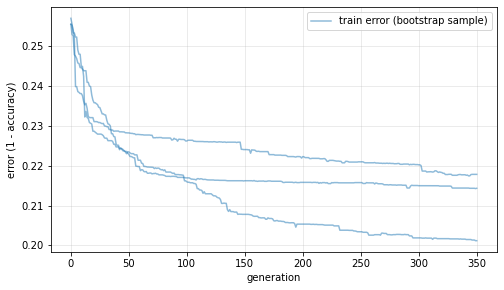

In [21]:
# convergence: error of the best individual per generation (lower is better), one line per run
plt.figure(figsize=(8, 4.5))
for r, (seed, hof, logbook) in enumerate(runs):
    plt.plot(logbook.select("gen"), logbook.select("min"), color='tab:blue', alpha=0.5,
             label="train error (bootstrap sample)" if r == 0 else None)
plt.xlabel("generation")
plt.ylabel("error (1 - accuracy)")
plt.legend()
plt.grid(alpha=0.3)
os.makedirs('figures', exist_ok=True)
plt.savefig('figures/convergence.png', dpi=200, bbox_inches='tight')
plt.show()

show the best individual of the best run as an expression (best validation accuracy, or best training accuracy when there is no validation set)

In [22]:
import textwrap

ensemble = [hof.items[0] for (_, hof, _) in runs]    # best individual of each run

if len(idx_val):
    scores = [accuracy(ind, X_val_ge, Y_val_ge) for ind in ensemble]
else:
    scores = [accuracy(ind, X_train_ge, Y_train_ge) for ind in ensemble]
best_run = int(np.argmax(scores))

print(f"Best single individual (run {best_run + 1}): \n", "\n".join(textwrap.wrap(str(ensemble[best_run]), 80)))
print("\nTraining Fitness: ", ensemble[best_run].fitness.values[0])

Best single individual (run 1): 
 or_(Soil_Type13, lt(ite(pdiv(multiply(Wilderness_Area1, Hydro_m_Road),
subtract(Fire_m_Road, ite(gt(multiply(add(0.73,
Horizontal_Distance_To_Fire_Points), not_(Soil_Type19)), Hydro_m_Road),
subtract(Soil_Type32, Elev_m_HDH), Aspect))), add(ite(add(Soil_Type22,
Soil_Type22), Wilderness_Area1, Hillshade_Noon),
subtract(gt(gt(multiply(Wilderness_Area1, Soil_Type32), subtract(or_(Soil_Type2,
Soil_Type32), subtract(Slope, subtract(Soil_Type29, ite(Hydro_p_Fire,
Soil_Type35, Wilderness_Area1))))), gt(Soil_Type27, Hydro_m_Road)),
Soil_Type32)), Elev_m_HDH), subtract(add(or_(subtract(Soil_Type32, Elev_m_VDH),
Soil_Type12), add(ite(Soil_Type32, ite(gt(Soil_Type20, Hydro_m_Road),
subtract(Soil_Type32, Elev_m_HDH), Aspect), Hillshade_Noon),
or_(subtract(add(or_(lt(Soil_Type32, lt(Elev_m_HDH3, Soil_Type29)),
lt(ite(Hydro_p_Fire, not_(or_(Hillshade_3pm, pdiv(Hydro_p_Fire,
Horizontal_Distance_To_Roadways))), Hillshade_3pm), Soil_Type32)),
add(subtract(ite(not_(or_(

## Explainability: how the evolved programs make their decisions

The terminals are named after the input features, so the programs printed above can be read directly. The cells below
1. count which features each evolved program uses,
2. list every simple threshold test (`feature < constant` or `feature > constant`), converted from z-scores back to the feature's real units, and
3. plot the most-used continuous feature for each class, with those cut-offs marked.

Figures are saved in a `figures/` folder next to the notebook.

In [23]:
from collections import Counter

def features_used(tree):
    # terminals whose value is a feature name (constants are numbers)
    return Counter(n.value for n in tree
                   if isinstance(n, gp.Terminal) and isinstance(n.value, str) and n.value in feature_cols)

best_tree = ensemble[best_run]

for k, ind in enumerate(ensemble):
    used = features_used(ind)
    tag = "   <- best single program" if k == best_run else ""
    print(f"Program {k + 1}: {len(ind)} nodes, height {ind.height}, {len(used)} distinct features{tag}")
    print("   most used:", used.most_common(8))

Program 1: 122 nodes, height 17, 25 distinct features   <- best single program
   most used: [('Soil_Type32', 11), ('Elev_m_HDH', 6), ('Wilderness_Area1', 5), ('Hydro_m_Road', 4), ('Hydro_p_Fire', 4), ('Soil_Type22', 3), ('Hillshade_Noon', 3), ('Hillshade_3pm', 3)]
Program 2: 117 nodes, height 17, 17 distinct features
   most used: [('Soil_Type27', 10), ('Elev_m_HDH', 8), ('Horizontal_Distance_To_Roadways', 7), ('Vertical_Distance_To_Hydrology', 5), ('Elev_m_HDH3', 5), ('Hillshade_Noon', 4), ('Soil_Type32', 3), ('Soil_Type33', 3)]
Program 3: 90 nodes, height 10, 17 distinct features
   most used: [('Elev_m_HDH', 7), ('Hillshade_Noon', 6), ('Soil_Type22', 5), ('Wilderness_Area1', 4), ('Hydro_p_Fire', 4), ('Hydro_m_Road', 4), ('Soil_Type32', 3), ('Aspect', 3)]


In [24]:
def to_original(feature, z):
    # undo the z-score of a continuous feature, using the training mean and standard deviation
    return z * sd[feature] + mu[feature]

def simple_thresholds(tree):
    # tests of the form  feature < constant  or  feature > constant  on continuous features,
    # with the constant converted to the feature's real units
    rows = []
    for i, node in enumerate(tree):
        if isinstance(node, gp.Primitive) and node.name in ('lt', 'gt'):
            a = tree.searchSubtree(i + 1)
            b = tree.searchSubtree(a.stop)
            left, right = tree[a], tree[b]
            if len(left) != 1 or len(right) != 1:
                continue                    # one side is an expression, not a single feature or constant
            l, r = left[0].value, right[0].value
            if isinstance(l, str) and isinstance(r, (int, float)):
                feat, z, op = l, r, ('<' if node.name == 'lt' else '>')
            elif isinstance(r, str) and isinstance(l, (int, float)):
                feat, z, op = r, l, ('>' if node.name == 'lt' else '<')   # constant < feature  means  feature > constant
            else:
                continue
            if feat in cont_cols:
                rows.append((feat, op, z, to_original(feat, z)))
    return rows

for k, ind in enumerate(ensemble):
    rows = simple_thresholds(ind)
    print(f"Program {k + 1}: {len(rows)} simple threshold test(s)")
    for feat, op, z, real in rows:
        print(f"   {feat} {op} {real:.1f}   (z-score threshold {z:+.2f})")

Program 1: 0 simple threshold test(s)
Program 2: 0 simple threshold test(s)
Program 3: 0 simple threshold test(s)


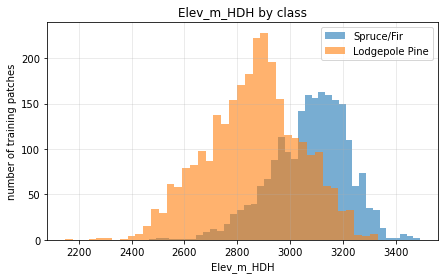

The best program has no simple 'Elev_m_HDH < constant' test: its comparisons involve expressions or other features, so there is no single cut-off to draw.


In [25]:
# distribution of the most-used continuous feature of the best program, by class
cont_used = [f for f, _ in features_used(best_tree).most_common() if f in cont_cols]
feat = cont_used[0] if cont_used else 'Elevation'
cuts = [real for f, op, z, real in simple_thresholds(best_tree) if f == feat]

plt.figure(figsize=(7, 4))
plt.hist(df_train.loc[Y_train == 0, feat], bins=40, alpha=0.6, label='Spruce/Fir')
plt.hist(df_train.loc[Y_train == 1, feat], bins=40, alpha=0.6, label='Lodgepole Pine')
for j, c in enumerate(cuts):
    plt.axvline(c, color='k', linestyle='--', label='evolved cut-off' if j == 0 else None)
plt.xlabel(feat)
plt.ylabel('number of training patches')
plt.title(f'{feat} by class')
plt.legend()
plt.grid(alpha=0.3)
os.makedirs('figures', exist_ok=True)
plt.savefig(f'figures/{feat}_histogram.png', dpi=200, bbox_inches='tight')
plt.show()

if not cuts:
    print(f"The best program has no simple '{feat} < constant' test: its comparisons involve expressions "
          f"or other features, so there is no single cut-off to draw.")

## Ensemble: majority vote

Each run gives a different evolved program. Their predictions are combined by majority vote (`VOTE_THRESHOLD = 0.5`: Lodgepole Pine when at least half of the programs say so).

In [26]:
VOTE_THRESHOLD = 0.5

def ensemble_predict(individuals, X):
    votes = np.mean([predict(ind, X) for ind in individuals], axis=0)
    return (votes >= VOTE_THRESHOLD).astype(int)

# accuracy of the single best individual vs the ensemble
sets = {'train': (X_train_ge, Y_train_ge), 'validation': (X_val_ge, Y_val_ge), 'all labelled': (X_all, Y_train)}
for name, (X_, Y_) in sets.items():
    if Y_.size:
        single = accuracy(ensemble[best_run], X_, Y_)
        voted = np.mean(ensemble_predict(ensemble, X_) == Y_)
        print(f"{name:>13}:  best single = {single:.4f} | ensemble of {len(ensemble)} = {voted:.4f}")

        train:  best single = 0.8025 | ensemble of 3 = 0.7965
   validation:  best single = 0.7960 | ensemble of 3 = 0.7870
 all labelled:  best single = 0.8012 | ensemble of 3 = 0.7946


Validation accuracy of the vote as ensemble members are added (members in run order).

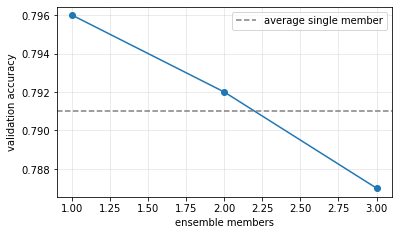

In [27]:
if len(idx_val):
    member_val = np.array([predict(ind, X_val_ge) for ind in ensemble])          # members x samples
    curve = [np.mean((member_val[:k].mean(axis=0) >= VOTE_THRESHOLD) == Y_val_ge)
             for k in range(1, len(ensemble) + 1)]
    plt.figure(figsize=(6, 3.5))
    plt.plot(range(1, len(curve) + 1), curve, marker='o')
    plt.axhline(np.mean([accuracy(ind, X_val_ge, Y_val_ge) for ind in ensemble]), color='gray',
                linestyle='--', label='average single member')
    plt.xlabel("ensemble members")
    plt.ylabel("validation accuracy")
    plt.legend()
    plt.grid(alpha=0.3)
    os.makedirs('figures', exist_ok=True)
    plt.savefig('figures/ensemble_size.png', dpi=200, bbox_inches='tight')
    plt.show()

Predict the classes of the test set.

Make sure you print here in the notebook you will submit to Brightspace the same predictions you used in your best submission to the Kaggle competition.

In [28]:
y_pred = ensemble_predict(ensemble, X_test)     # 0 = Spruce/Fir, 1 = Lodgepole Pine (majority vote)
print("Predicted classes of the test set (0/1): ", y_pred)
print("Share predicted Lodgepole Pine: test = %.3f | train = %.3f" % (y_pred.mean(), Y_train.mean()))

Predicted classes of the test set (0/1):  [1 0 0 ... 1 0 1]
Share predicted Lodgepole Pine: test = 0.617 | train = 0.572


Write a code to create a .csv with the following format:
1. First column is named `id` (from 0 to 490140);
2. Second column is named `Cover_Type` and contains the predictions (only 1's or 2's) you got in the previous cell with y_pred (0 -> 1 Spruce/Fir, 1 -> 2 Lodgepole Pine).

Example:

    id,Cover_Type

    0,1

    1,1

    2,2

    ...

    490140,1

Submit it to the competition and check your score there.

In [29]:
submission = pd.DataFrame({'id': test_ids, 'Cover_Type': y_pred + 1})
submission.to_csv('submissiongp.csv', index=False)

print(submission.shape, '| expected (490141, 2)')
print(submission['Cover_Type'].value_counts())
submission.head()

(490141, 2) | expected (490141, 2)
2    302652
1    187489
Name: Cover_Type, dtype: int64


,id,Cover_Type
0,0,2
1,1,1
2,2,1
3,3,1
4,4,2
